<a href="https://colab.research.google.com/github/SumaiyaData/Predicting-Plant-Based-Meat-Texture/blob/main/Predicting_Plant_Based_Meat_Texture.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   no WG_frac  protein  target moisture  moisture     ash   carbs    fat  \
0   1       0  62.6988            56.85    5.3937  4.2445  20.491  6.662   
1   2       0  62.6988            56.85    5.3937  4.2445  20.491  6.662   
2   3       0  62.6988            57.16    5.3937  4.2445  20.491  6.662   
3   4      10  63.1788            57.51    5.9137  3.9545  19.861  6.582   
4   5      10  63.1788            57.24    5.9137  3.9545  19.861  6.582   

   fiber  Hardness  Chewiness  Group_ID  Study_ID Unnamed: 13      Unnamed: 14  
0   0.51   46.7090  38.049816         5         2   ext._0%WG   extrusion_0%WG  
1   0.51   40.4365  31.294988         5         2   ext._0%WG   extrusion_0%WG  
2   0.51   49.0595  39.494747         5         2   ext._0%WG   extrusion_0%WG  
3   0.51   38.6525  26.862429         6         2  ext._10%WG  extrusion_10%WG  
4   0.51   50.8115  38.977081         6         2  ext._10%WG  extrusion_10%WG  


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 15/15 [00:00<00:00, 64.55it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

... (30 outputs left out)


Test Predictions: Hardness


,Group_ID,Actual,Predicted,Absolute_Error,Error
0,10,74.374,93.081,18.706,-18.706
1,10,70.018,93.346,23.328,-23.328
2,10,67.650,93.333,25.683,-25.683
3,11,69.774,56.787,12.986,12.986
4,11,65.300,60.920,4.380,4.380
5,11,65.460,56.551,8.909,8.909
6,1,21.844,25.820,3.975,-3.975
7,1,24.833,25.820,0.986,-0.986
8,1,26.284,25.820,0.464,0.464
9,1,23.412,25.595,2.183,-2.183



Test Predictions: Chewiness


,Group_ID,Actual,Predicted,Absolute_Error,Error
0,10,64.850,75.833,10.983,-10.983
1,10,58.412,76.038,17.626,-17.626
2,10,53.782,76.031,22.248,-22.248
3,11,58.304,44.973,13.331,13.331
4,11,54.780,41.825,12.955,12.955
5,11,55.666,44.926,10.740,10.740
6,1,19.110,21.391,2.281,-2.281
7,1,21.570,21.391,0.178,0.178
8,1,23.069,21.391,1.678,1.678
9,1,19.806,21.187,1.381,-1.381


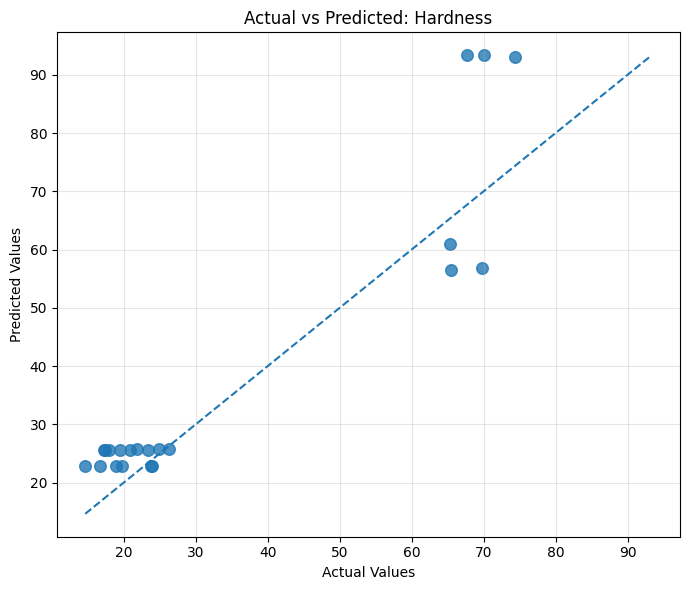

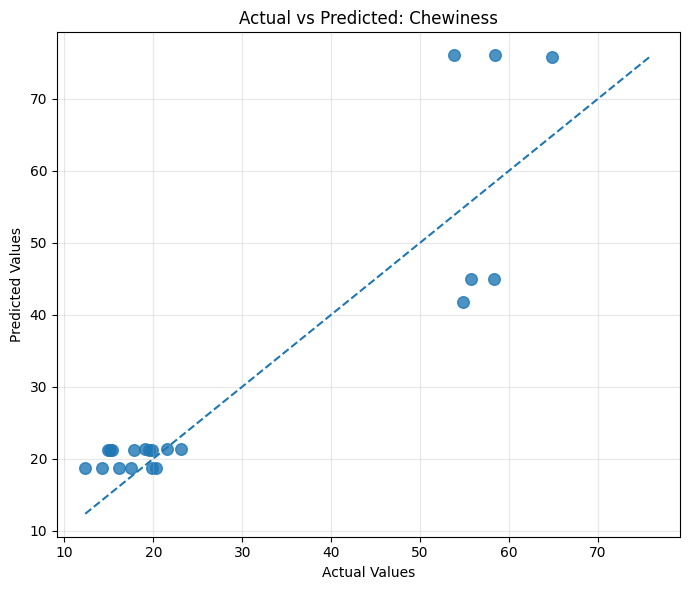

In [2]:
#Loading Libraries

%pip install -q -U "fg-data-profiling[notebook]" xgboost

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from data_profiling import ProfileReport
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit, LeaveOneGroupOut, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.neighbors import KNeighborsRegressor, NearestNeighbors
from sklearn.neural_network import MLPRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline,make_pipeline
from sklearn.feature_selection import SelectKBest,chi2
from sklearn.tree import DecisionTreeClassifier

# Loading and checking the dataset

Dataset_original = pd.read_csv('/content/additional_30_12_12.csv')
meat_texture = Dataset_original.copy()
print(meat_texture.head(5))
profile = ProfileReport(meat_texture, title="Plant-Based Meat Dataset - Complete Profiling Report", explorative=True, minimal=False)
profile.to_notebook_iframe()
profile.to_file("/content/Complete_Dataset_Profiling_Report.html")
meat_texture.info()
meat_texture = meat_texture.drop(columns=["no", "WG_frac", "Unnamed: 13", "Unnamed: 14"])
meat_texture.head(5)


# Applying main analysis

X = meat_texture.drop(columns=["Hardness", "Chewiness", "Group_ID", "Study_ID"])
y = meat_texture[["Hardness", "Chewiness"]]

# Create group-aware split
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=meat_texture["Group_ID"]))

# Separate training and testing data
X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

# Verify group separation
train_groups = set(meat_texture["Group_ID"].iloc[train_idx])
test_groups = set(meat_texture["Group_ID"].iloc[test_idx])

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("Training groups:", sorted(train_groups))
print("Testing groups:", sorted(test_groups))

print("Common groups:", train_groups.intersection(test_groups))



# Prepare training group identifiers
groups_train = meat_texture["Group_ID"].iloc[train_idx].reset_index(drop=True)

# Reset indices for consistency
X_train = X_train.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)

# Verify training data
print("Training observations:", len(X_train))
print("Training groups:", groups_train.nunique())

print("\nTraining group distribution:")
display(groups_train.value_counts().sort_index())


# Create Leave-One-Group-Out cross-validation
logo = LeaveOneGroupOut()

# Check the number of LOGO validation rounds

print("Number of LOGO folds:",
      logo.get_n_splits(X_train, y_train, groups=groups_train))


# ==========================================
# DEFINE REGRESSION MODELS
# ==========================================

models = {

    # 1. Ridge Regression
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0))
    ]),

    # 2. K-Nearest Neighbors
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsRegressor(
            n_neighbors=3,
            weights="distance"
        ))
    ]),

    # 3. Gaussian Process Regression
    "GPR": Pipeline([
        ("scaler", StandardScaler()),
        ("model", GaussianProcessRegressor(
            kernel=(
                ConstantKernel(1.0) *
                Matern(length_scale=1.0, nu=2.5) +
                WhiteKernel(noise_level=1.0)
            ),
            normalize_y=True,
            n_restarts_optimizer=2,
            random_state=42
        ))
    ]),

    # 4. Random Forest
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42
    ),

    # 5. Extra Trees
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42
    )
}

print("Regression models prepared:")
for name in models:
    print(name)


# ==========================================
# LOGO CROSS-VALIDATION
# ==========================================

results = []

oof_predictions = {}

for name, model in models.items():

    print(f"\nEvaluating: {name}")

    # Generate predictions using LOGO
    y_pred = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=logo,
        groups=groups_train
    )

    oof_predictions[name] = y_pred

    # Calculate metrics separately for each target
    for i, target in enumerate(y_train.columns):

        mae = mean_absolute_error(
            y_train.iloc[:, i],
            y_pred[:, i]
        )

        rmse = np.sqrt(
            mean_squared_error(
                y_train.iloc[:, i],
                y_pred[:, i]
            )
        )

        r2 = r2_score(
            y_train.iloc[:, i],
            y_pred[:, i]
        )

        results.append({
            "Model": name,
            "Target": target,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })


# Create results dataframe
results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        ["Target", "RMSE"]
    ).reset_index(drop=True)
)


# ==========================================
# INSPECT ACTUAL VS PREDICTED VALUES
# ==========================================

for model_name in ["GPR", "Ridge"]:

    print(f"\n========== {model_name} ==========")

    predictions = oof_predictions[model_name]

    for i, target in enumerate(y_train.columns):

        comparison = pd.DataFrame({
            "Group_ID": groups_train,
            "Actual": y_train[target],
            "Predicted": predictions[:, i]
        })

        comparison["Error"] = (
            comparison["Actual"] -
            comparison["Predicted"]
        )

        print(f"\nTarget: {target}")

        display(comparison.round(3))

        print("Actual range:",
              comparison["Actual"].min(),
              "to",
              comparison["Actual"].max())

        print("Predicted range:",
              comparison["Predicted"].min(),
              "to",
              comparison["Predicted"].max())


# ==========================================
# GROUP-WISE PREDICTION ERROR ANALYSIS
# ==========================================

for model_name in ["GPR", "Ridge"]:

    print(f"\n========== {model_name} ==========")

    predictions = oof_predictions[model_name]

    for i, target in enumerate(y_train.columns):

        comparison = pd.DataFrame({

            "Group_ID": groups_train.to_numpy(),

            "Actual": y_train[target].to_numpy(),

            "Predicted": predictions[:, i]
        })

        comparison["Absolute_Error"] = abs(
            comparison["Actual"] -
            comparison["Predicted"]
        )

        comparison["Prediction_Error"] = (
            comparison["Actual"] -
            comparison["Predicted"]
        )

        group_summary = comparison.groupby(
            "Group_ID"
        ).agg(

            Observations=("Actual", "count"),

            Actual_Mean=("Actual", "mean"),

            Predicted_Mean=("Predicted", "mean"),

            MAE=("Absolute_Error", "mean"),

            Mean_Error=("Prediction_Error", "mean")

        ).round(3)

        print(f"\nTarget: {target}")

        display(group_summary)


group_study_check = (
    meat_texture.groupby("Group_ID")["Study_ID"].nunique()
)

print(group_study_check)

print(
    "\nGroup IDs appearing in multiple studies:",
    group_study_check[group_study_check > 1]
)


# ==========================================
# CHECK GROUP-WISE FEATURE DISTRIBUTION
# ==========================================

feature_diagnostics = []

for held_group in sorted(groups_train.unique()):

    validation_mask = groups_train == held_group

    X_validation = X_train.loc[validation_mask]

    X_reference = X_train.loc[~validation_mask]

    for column in X_train.columns:

        reference_min = X_reference[column].min()
        reference_max = X_reference[column].max()

        validation_min = X_validation[column].min()
        validation_max = X_validation[column].max()

        outside_range = (
            validation_min < reference_min or
            validation_max > reference_max
        )

        feature_diagnostics.append({

            "Group_ID": held_group,

            "Feature": column,

            "Validation_Min": validation_min,

            "Validation_Max": validation_max,

            "Training_Min": reference_min,

            "Training_Max": reference_max,

            "Outside_Training_Range": outside_range

        })

feature_diagnostics_df = pd.DataFrame(feature_diagnostics)

# Examine Group 9
display(
    feature_diagnostics_df[
        feature_diagnostics_df["Group_ID"] == 9
    ].round(3)
)



# ==========================================
# BASELINE MODEL: DUMMY REGRESSOR
# ==========================================

from sklearn.dummy import DummyRegressor

baseline_results = []

baseline_predictions = {}

for target in y_train.columns:

    print(f"\nEvaluating baseline for: {target}")

    baseline_model = DummyRegressor(strategy="mean")

    y_pred = cross_val_predict(
        baseline_model,
        X_train,
        y_train[target],
        cv=logo,
        groups=groups_train
    )

    baseline_predictions[target] = y_pred

    mae = mean_absolute_error(
        y_train[target], y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(y_train[target], y_pred)
    )

    r2 = r2_score(
        y_train[target], y_pred
    )

    baseline_results.append({
        "Model": "Dummy Baseline",
        "Target": target,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

baseline_df = pd.DataFrame(baseline_results)

display(baseline_df)



# ==========================================
# BASELINE VS MACHINE LEARNING COMPARISON
# ==========================================

# Combine ML model results and baseline results
comparison_results = pd.concat(
    [results_df, baseline_df],
    ignore_index=True
)

# Sort results by target and RMSE
comparison_results = comparison_results.sort_values(
    ["Target", "RMSE"]
).reset_index(drop=True)

display(comparison_results.round(4))


# ==========================================
# CALCULATE IMPROVEMENT OVER BASELINE
# ==========================================

improvement_results = []

for target in y_train.columns:

    baseline_rmse = baseline_df.loc[
        baseline_df["Target"] == target, "RMSE"
    ].iloc[0]

    baseline_mae = baseline_df.loc[
        baseline_df["Target"] == target, "MAE"
    ].iloc[0]

    for _, row in results_df[
        results_df["Target"] == target
    ].iterrows():

        rmse_improvement = (
            (baseline_rmse - row["RMSE"])
            / baseline_rmse
        ) * 100

        mae_improvement = (
            (baseline_mae - row["MAE"])
            / baseline_mae
        ) * 100

        improvement_results.append({
            "Target": target,
            "Model": row["Model"],
            "RMSE Improvement (%)": rmse_improvement,
            "MAE Improvement (%)": mae_improvement,
            "R2": row["R2"]
        })

improvement_df = pd.DataFrame(improvement_results)

display(improvement_df.round(3))



# ==========================================
# HYPERPARAMETER TUNING USING LOGO
# ==========================================

from sklearn.model_selection import GridSearchCV

# Define models and parameter grids

tuning_models = {

    "Ridge": {
        "estimator": Pipeline([
            ("scaler", StandardScaler()),
            ("model", Ridge())
        ]),
        "params": {
            "model__alpha": [0.01, 0.1, 1, 10, 100, 1000]
        }
    },

    "KNN": {
        "estimator": Pipeline([
            ("scaler", StandardScaler()),
            ("model", KNeighborsRegressor())
        ]),
        "params": {
            "model__n_neighbors": [2, 3, 5, 7],
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2]
        }
    },

    "GPR": {
        "estimator": Pipeline([
            ("scaler", StandardScaler()),
            ("model", GaussianProcessRegressor(
                kernel=(
                    ConstantKernel(1.0) *
                    Matern(length_scale=1.0, nu=2.5) +
                    WhiteKernel(noise_level=1.0)
                ),
                normalize_y=True,
                n_restarts_optimizer=2,
                random_state=42
            ))
        ]),
        "params": {}
    },

    "Random Forest": {
        "estimator": RandomForestRegressor(
            random_state=42
        ),
        "params": {
            "n_estimators": [200, 500],
            "max_depth": [None, 3, 5],
            "min_samples_leaf": [1, 2, 3],
            "max_features": [1.0, "sqrt"]
        }
    },

    "Extra Trees": {
        "estimator": ExtraTreesRegressor(
            random_state=42
        ),
        "params": {
            "n_estimators": [200, 500],
            "max_depth": [None, 3, 5],
            "min_samples_leaf": [1, 2, 3],
            "max_features": [1.0, "sqrt"]
        }
    }
}


# Store tuning results and best models

tuning_results = []

best_models = {}


# Tune each target separately

for target in y_train.columns:

    print(f"\n========== TUNING TARGET: {target} ==========")

    for model_name, config in tuning_models.items():

        print(f"\nTuning {model_name}...")

        search = GridSearchCV(
            estimator=config["estimator"],
            param_grid=config["params"],
            scoring="neg_root_mean_squared_error",
            cv=logo,
            n_jobs=-1,
            refit=True
        )

        search.fit(
            X_train,
            y_train[target],
            groups=groups_train
        )

        best_models[(target, model_name)] = search.best_estimator_

        tuning_results.append({

            "Target": target,

            "Model": model_name,

            "Best_LOGO_RMSE": -search.best_score_,

            "Best_Parameters": search.best_params_

        })

        print("Best LOGO RMSE:", -search.best_score_)
        print("Best parameters:", search.best_params_)


# Create tuning results table

tuning_results_df = pd.DataFrame(tuning_results)

display(
    tuning_results_df.sort_values(
        ["Target", "Best_LOGO_RMSE"]
    ).reset_index(drop=True)
)



# ==========================================
# FINAL MODEL SELECTION
# ==========================================

best_model_names = {}

final_models = {}

for target in y_train.columns:

    target_results = tuning_results_df[
        tuning_results_df["Target"] == target
    ]

    best_row = target_results.loc[
        target_results["Best_LOGO_RMSE"].idxmin()
    ]

    best_model_name = best_row["Model"]

    best_model_names[target] = best_model_name

    final_models[target] = best_models[
        (target, best_model_name)
    ]

    print(f"\nTarget: {target}")
    print("Selected model:", best_model_name)
    print("Best LOGO RMSE:", best_row["Best_LOGO_RMSE"])
    print("Best parameters:", best_row["Best_Parameters"])


# ==========================================
# FINAL TEST SET EVALUATION
# ==========================================

test_results = []

final_predictions = {}

groups_test = meat_texture["Group_ID"].iloc[
    test_idx
].reset_index(drop=True)

X_test_final = X_test.reset_index(drop=True)
y_test_final = y_test.reset_index(drop=True)


for target in y_train.columns:

    print(f"\n========== {target} ==========")

    # Selected model
    best_model = final_models[target]

    # Predict on untouched test data
    y_pred = best_model.predict(X_test_final)

    final_predictions[target] = y_pred

    # Evaluate selected model
    mae = mean_absolute_error(
        y_test_final[target], y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test_final[target], y_pred
        )
    )

    r2 = r2_score(
        y_test_final[target], y_pred
    )

    test_results.append({
        "Target": target,
        "Model": best_model_names[target],
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    # Evaluate Dummy Baseline on the same test data
    baseline_model = DummyRegressor(strategy="mean")

    baseline_model.fit(
        X_train, y_train[target]
    )

    baseline_pred = baseline_model.predict(
        X_test_final
    )

    baseline_mae = mean_absolute_error(
        y_test_final[target], baseline_pred
    )

    baseline_rmse = np.sqrt(
        mean_squared_error(
            y_test_final[target], baseline_pred
        )
    )

    baseline_r2 = r2_score(
        y_test_final[target], baseline_pred
    )

    test_results.append({
        "Target": target,
        "Model": "Dummy Baseline",
        "MAE": baseline_mae,
        "RMSE": baseline_rmse,
        "R2": baseline_r2
    })


# ==========================================
# FINAL PERFORMANCE TABLE
# ==========================================

final_results_df = pd.DataFrame(test_results)

display(final_results_df.round(4))


# ==========================================
# ACTUAL VS PREDICTED TEST VALUES
# ==========================================

for target in y_train.columns:

    comparison = pd.DataFrame({

        "Group_ID": groups_test,

        "Actual": y_test_final[target],

        "Predicted": final_predictions[target]

    })

    comparison["Absolute_Error"] = abs(
        comparison["Actual"] -
        comparison["Predicted"]
    )

    comparison["Error"] = (
        comparison["Actual"] -
        comparison["Predicted"]
    )

    print(f"\nTest Predictions: {target}")

    display(comparison.round(3))



# ACTUAL VS PREDICTED PLOTS

for target in y_train.columns:

    actual = y_test_final[target]

    predicted = final_predictions[target]

    plt.figure(figsize=(7, 6))

    plt.scatter(actual, predicted, s=70, alpha=0.8)

    # Perfect prediction reference line
    min_value = min(actual.min(), predicted.min())
    max_value = max(actual.max(), predicted.max())

    plt.plot(
        [min_value, max_value],
        [min_value, max_value],
        linestyle="--"
    )

    plt.xlabel("Actual Values")
    plt.ylabel("Predicted Values")

    plt.title(f"Actual vs Predicted: {target}")

    plt.grid(alpha=0.3)

    plt.tight_layout()

    plt.show()
